In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đọc dữ liệu từ thư mục raw
csv_path = Path("../data/raw/StudentPerformanceFactors.csv")

if not csv_path.exists():
    csv_path = Path("data/raw/StudentPerformanceFactors.csv")

df = pd.read_csv(csv_path)

# Giữ bản sao để đối chiếu
df_raw = df.copy()

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
print("Số dòng, số cột:", df.shape)

print("\nTên các cột:")
print(df.columns.tolist())

print("\nThông tin dữ liệu:")
df.info()

print("\nThống kê dữ liệu:")
display(df.describe(include="all").T)

print("\nSố dòng trùng lặp:", df.duplicated().sum())

Số dòng, số cột: (6607, 20)

Tên các cột:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Thông tin dữ liệu:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previ

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0



Số dòng trùng lặp: 0


In [5]:
# Chuẩn hóa tên cột
df.columns = df.columns.str.strip()

# Chuẩn hóa khoảng trắng trong các cột dạng chữ
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

print("Đã chuẩn hóa dữ liệu dạng chữ.")
display(df.head())

Đã chuẩn hóa dữ liệu dạng chữ.


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [6]:
duplicates = df.duplicated().sum()

print("Số dòng trùng trước khi xử lý:", duplicates)

df = df.drop_duplicates().copy()

print("Số dòng trùng sau khi xử lý:", df.duplicated().sum())
print("Kích thước mới:", df.shape)

Số dòng trùng trước khi xử lý: 0
Số dòng trùng sau khi xử lý: 0
Kích thước mới: (6607, 20)


In [8]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percent": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percent",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percent
Parental_Education_Level,90,1.36
Teacher_Quality,78,1.18
Distance_from_Home,67,1.01
Hours_Studied,0,0.00
Access_to_Resources,0,0.00
Parental_Involvement,0,0.00
Attendance,0,0.00
Extracurricular_Activities,0,0.00
Motivation_Level,0,0.00
Internet_Access,0,0.00


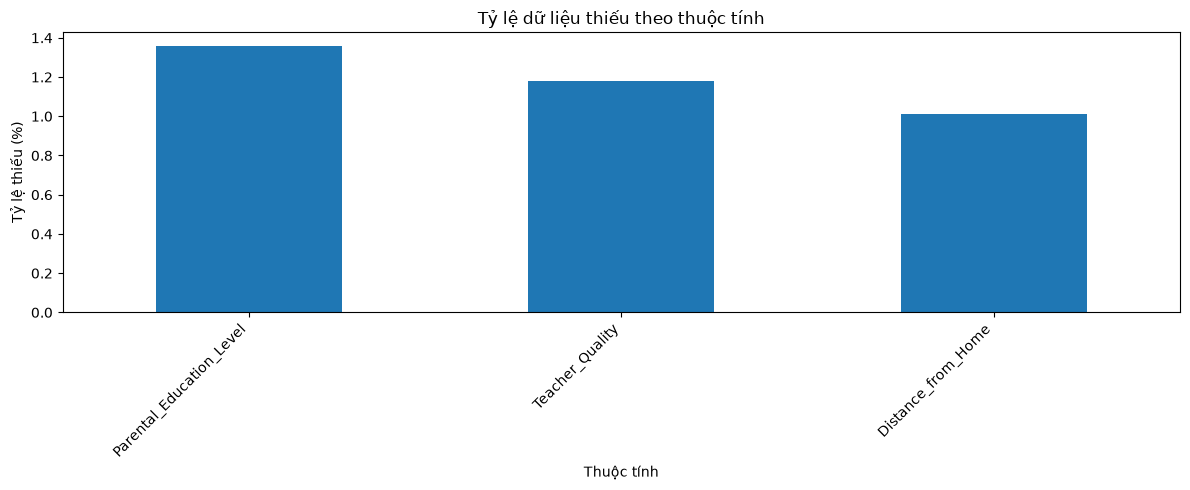

In [9]:
missing_plot = missing_report[
    missing_report["Missing_Count"] > 0
]

if not missing_plot.empty:
    missing_plot["Missing_Percent"].plot(
        kind="bar",
        figsize=(12, 5)
    )
    plt.title("Tỷ lệ dữ liệu thiếu theo thuộc tính")
    plt.ylabel("Tỷ lệ thiếu (%)")
    plt.xlabel("Thuộc tính")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Không có giá trị thiếu.")

In [10]:
range_rules = {
    "Hours_Studied": (0, 168),  # Số giờ trong 1 tuần: 7 * 24
    "Attendance": (0, 100),     # Tỷ lệ chuyên cần (%)
    "Sleep_Hours": (0, 24),     # Số giờ ngủ trong 1 ngày
}

for col, (lower, upper) in range_rules.items():
    if col in df.columns:
        invalid = df[
            df[col].notna()
            & ~df[col].between(lower, upper)
        ]

        print(
            f"{col}: {len(invalid)} giá trị ngoài khoảng "
            f"[{lower}, {upper}]"
        )

        if not invalid.empty:
            display(invalid[[col]].head(10))

Hours_Studied: 0 giá trị ngoài khoảng [0, 168]
Attendance: 0 giá trị ngoài khoảng [0, 100]
Sleep_Hours: 0 giá trị ngoài khoảng [0, 24]


In [11]:
numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

outlier_results = []

for col in numeric_columns:
    values = df[col].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((values < lower) | (values > upper)).sum()

    outlier_results.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": int(count)
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

,Column,Q1,Q3,Lower_Bound,Upper_Bound,Outlier_Count
0,Hours_Studied,16.0,24.0,4.0,36.0,43
1,Attendance,70.0,90.0,40.0,120.0,0
2,Sleep_Hours,6.0,8.0,3.0,11.0,0
3,Previous_Scores,63.0,88.0,25.5,125.5,0
4,Tutoring_Sessions,1.0,2.0,-0.5,3.5,430
5,Physical_Activity,2.0,4.0,-1.0,7.0,0
6,Exam_Score,65.0,69.0,59.0,75.0,104


In [13]:
print("Kích thước ban đầu:", df_raw.shape)
print("Kích thước sau làm sạch:", df.shape)

print("\nSố dòng trùng còn lại:", df.duplicated().sum())

print("\nGiá trị thiếu còn lại:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nNăm dòng đầu:")
display(df.head())

Kích thước ban đầu: (6607, 20)
Kích thước sau làm sạch: (6607, 20)

Số dòng trùng còn lại: 0

Giá trị thiếu còn lại:


,Missing_Count
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0



Năm dòng đầu:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [14]:
print("Kích thước ban đầu:", df_raw.shape)
print("Kích thước sau làm sạch:", df.shape)

print("\nSố dòng trùng còn lại:", df.duplicated().sum())

print("\nGiá trị thiếu còn lại:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nNăm dòng đầu:")
display(df.head())

Kích thước ban đầu: (6607, 20)
Kích thước sau làm sạch: (6607, 20)

Số dòng trùng còn lại: 0

Giá trị thiếu còn lại:


,Missing_Count
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0



Năm dòng đầu:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [15]:
output_path = Path("../data/processed/StudentPerformanceFactors_cleaned.csv")

if not output_path.parent.exists():
    output_path = Path("data/processed/StudentPerformanceFactors_cleaned.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu dữ liệu sạch tại:", output_path.resolve())

Đã lưu dữ liệu sạch tại: C:\Users\minh\.vscode\Artificial-Intelligence-Student-performance-prediction\data\processed\StudentPerformanceFactors_cleaned.csv


In [20]:
# Đếm số giá trị bằng 101 trước khi sửa
print("Số điểm 101 trước khi sửa:", (df["Exam_Score"] == 101).sum())

# Thay điểm 101 thành 100
df.loc[df["Exam_Score"] == 101, "Exam_Score"] = 100

# Kiểm tra kết quả
print("Số điểm 101 sau khi sửa:", (df["Exam_Score"] == 101).sum())
print("Số điểm 100 sau khi sửa:", (df["Exam_Score"] == 100).sum())

# Hiển thị các bản ghi có điểm 100
display(df[df["Exam_Score"] == 100])

Số điểm 101 trước khi sửa: 0
Số điểm 101 sau khi sửa: 0
Số điểm 100 sau khi sửa: 2


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
94,18,89,High,Medium,Yes,4,73,Medium,Yes,3,High,Medium,Private,Positive,2,No,College,Near,Female,100
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,100
